# Прогноз курса Ethereum по 4 криптовалютам: LSTM + attention на PyTorch

**Задача:** по окну из последних 30 дней признаков BTC, ETH, SOL и USDT предсказать цену закрытия ETH на следующий день.

* модель предсказывает лог-доходность ETH, цена восстанавливается как `close_t * exp(r̂)`;
* признаки каждой монеты: лог-доходность, дневной размах `log(high/low)`, изменение объёма; у USDT цена ≈ 1$, поэтому вместо цены берём изменение капитализации (приток денег в стейблкоин);
* модель — LSTM + self-attention по временной оси, матрица внимания выводится и визуализируется;
* оценка — walk-forward на 5 последовательных тестовых кусках по 90 дней (обучение на всей истории до куска), сравнение с наивным прогнозом «завтра = сегодня».

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

torch.manual_seed(0); np.random.seed(0)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
W, TEST, FOLDS = 30, 90, 5

## Данные

In [2]:
num = lambda s: pd.to_numeric(s.astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")

def load(f):
    d = pd.read_csv(f"crypta/{f}", parse_dates=["Дата"], index_col="Дата").sort_index()
    return pd.DataFrame({"close": num(d["Закрыть"]), "high": num(d["Макс"]), "low": num(d["Мин"]),
                         "vol": num(d["Объём"]), "cap": num(d["Капитализ."])})

btc = pd.read_csv("crypta/btcusd_1-min_data.csv")
btc.index = pd.to_datetime(btc.pop("Timestamp"), unit="s")
btc = btc.resample("D").agg({"Close": "last", "High": "max", "Low": "min", "Volume": "sum"})
btc.columns = ["close", "high", "low", "vol"]

assets = {"btc": btc, "eth": load("ethereum-historical-data.csv"),
          "sol": load("solana-historical-data (4).csv"), "usdt": load("tether-historical-data (2).csv")}

feats = []
for k, d in assets.items():
    f = pd.DataFrame({"ret": np.log(d.close).diff(), "hl": np.log(d.high / d.low), "vol": np.log1p(d.vol).diff()})
    if k == "usdt": f = pd.DataFrame({"vol": f.vol, "cap": np.log(d.cap).diff()})
    feats.append(f.add_prefix(k + "_"))
X = pd.concat(feats, axis=1, join="inner").dropna()
price = assets["eth"].close.reindex(X.index)
print(X.shape, X.index.min().date(), "->", X.index.max().date())
X.describe().T.round(4)

(1096, 11) 2022-06-10 -> 2025-06-09


,count,mean,std,min,25%,50%,75%,max
btc_ret,1096.0,0.0012,0.0271,-0.1690,-0.0108,-0.0001,0.0132,0.1125
btc_hl,1096.0,0.0385,0.0251,0.0039,0.0213,0.0329,0.0484,0.2031
btc_vol,1096.0,0.0002,0.6510,-2.1011,-0.3818,0.0160,0.4255,2.1380
eth_ret,1096.0,0.0003,0.0359,-0.1876,-0.0146,0.0000,0.0161,0.1923
eth_hl,1096.0,0.0444,0.0310,0.0037,0.0246,0.0369,0.0544,0.2171
eth_vol,1096.0,0.0005,0.4408,-1.2227,-0.2719,-0.0012,0.2787,2.0130
sol_ret,1096.0,0.0012,0.0513,-0.5367,-0.0265,-0.0011,0.0273,0.2836
sol_hl,1096.0,0.0674,0.0430,0.0095,0.0408,0.0567,0.0833,0.6556
sol_vol,1096.0,0.0009,0.4367,-1.1702,-0.2910,-0.0134,0.2668,1.6301
usdt_vol,1096.0,0.0008,0.3120,-0.9262,-0.1821,-0.0082,0.1872,1.2663


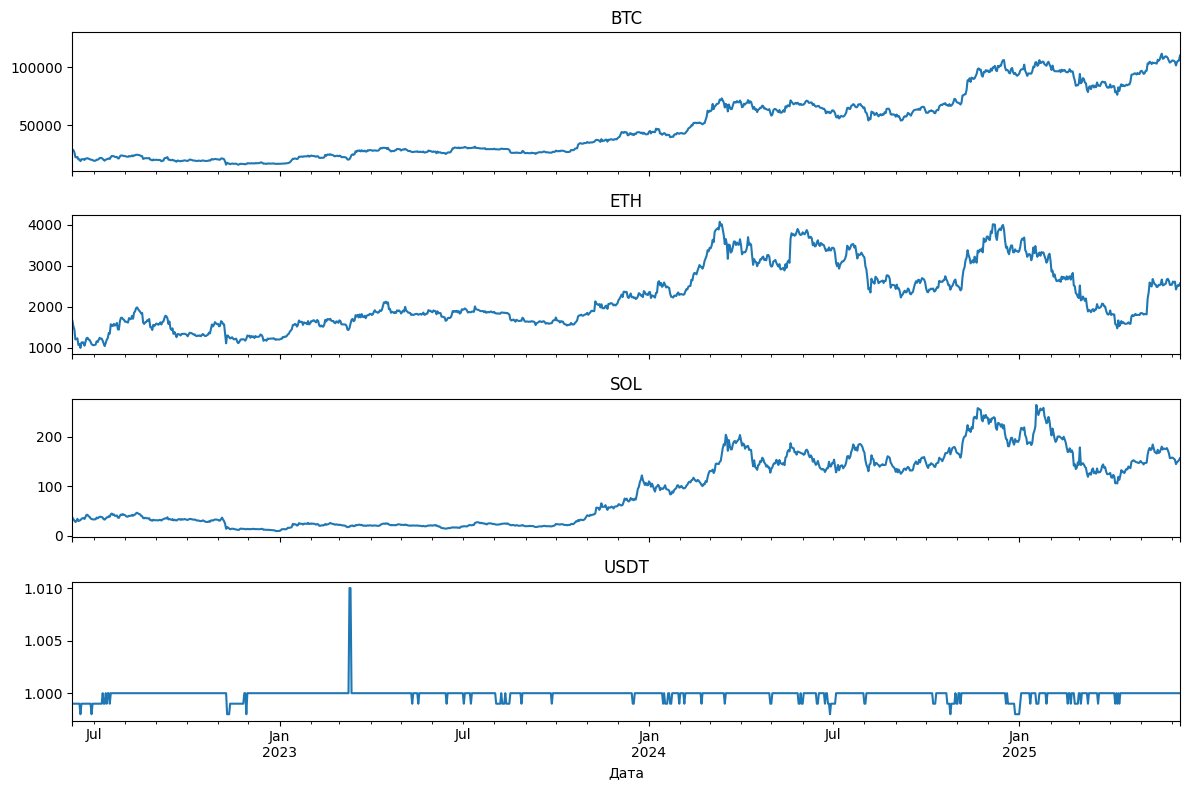

In [3]:
fig, ax = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for a, (k, d) in zip(ax, assets.items()):
    d.close.loc[X.index[0]:].plot(ax=a, title=k.upper())
plt.tight_layout()

## Модель

Окно `30 × n_features` → двухслойная **LSTM** (скрытые состояния по каждому дню) → **self-attention** (`MultiheadAttention`, 4 головы) поверх состояний LSTM с residual + LayerNorm → MLP-голова по последнему дню.

LSTM кодирует историю последовательно, а внимание позволяет напрямую связать любой день окна с любым другим. Матрица весов внимания `30×30` выводится и визуализируется.

In [4]:
class LSTMAttn(nn.Module):
    def __init__(s, n_in, d=64):
        super().__init__()
        s.lstm = nn.LSTM(n_in, d, num_layers=2, dropout=0.2, batch_first=True)
        s.att = nn.MultiheadAttention(d, 4, dropout=0.1, batch_first=True)
        s.norm = nn.LayerNorm(d)
        s.head = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Dropout(0.2), nn.Linear(d, 1))

    def forward(s, x):
        h, _ = s.lstm(x)
        a, w = s.att(h, h, h)
        h = s.norm(h + a)
        return s.head(h[:, -1]).squeeze(-1), w


def windows(A, y, idx):
    return (torch.tensor(np.stack([A[i - W + 1:i + 1] for i in idx]), dtype=torch.float32, device=DEV),
            torch.tensor(y[idx], dtype=torch.float32, device=DEV))


def fit(Xtr, ytr, Xva, yva, epochs=150):
    m = LSTMAttn(Xtr.shape[-1]).to(DEV)
    opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=1e-2)
    loss_fn, best = nn.HuberLoss(), (np.inf, None)
    for _ in range(epochs):
        m.train()
        for b in torch.randperm(len(Xtr), device=DEV).split(64):
            opt.zero_grad(); loss_fn(m(Xtr[b])[0], ytr[b]).backward(); opt.step()
        m.eval()
        with torch.no_grad(): v = loss_fn(m(Xva)[0], yva).item()
        if v < best[0]: best = (v, {k: t.clone() for k, t in m.state_dict().items()})
    m.load_state_dict(best[1]); m.eval()
    return m

## Walk-forward на 5 временных кусках

Для каждого куска: скейлер обучается только на train, последние 60 дней train — валидация для early stopping, ансамбль из 3 сидов.

In [5]:
target = X["eth_ret"].shift(-1).values
n, res, preds, attn = len(X), [], [], None

for k in range(FOLDS):
    t0 = n - 1 - (FOLDS - k) * TEST
    te = np.arange(t0, t0 + TEST)
    tr, va = np.arange(W - 1, t0 - 60), np.arange(t0 - 60, t0)
    sx = StandardScaler().fit(X.values[:t0]); A = sx.transform(X.values)
    sy = target[tr].std(); y = target / sy
    Xtr, ytr = windows(A, y, tr); Xva, yva = windows(A, y, va); Xte, _ = windows(A, y, te)

    outs = []
    for seed in range(3):
        torch.manual_seed(seed)
        m = fit(Xtr, ytr, Xva, yva)
        with torch.no_grad():
            p, w = m(Xte)
        outs.append(p.cpu().numpy() * sy)
    r_hat = np.mean(outs, 0)

    p_now = price.values[te]
    true, pred = price.values[te + 1], p_now * np.exp(r_hat)
    rmse = lambda a: np.sqrt(np.mean((a - true) ** 2))
    res.append({"кусок": f"{X.index[te[0] + 1].date()} — {X.index[te[-1] + 1].date()}",
                "RMSE модель": rmse(pred), "RMSE наивный": rmse(p_now),
                "MAPE модель, %": np.mean(np.abs(pred / true - 1)) * 100,
                "MAPE наивный, %": np.mean(np.abs(p_now / true - 1)) * 100,
                "точность направления, %": np.mean(np.sign(r_hat) == np.sign(target[te])) * 100})
    preds.append(pd.DataFrame({"факт": true, "модель": pred}, index=X.index[te + 1]))
    attn = w.mean(0).cpu().numpy()

res = pd.DataFrame(res).set_index("кусок")
res.loc["среднее"] = res.mean()
res.round(2)

,RMSE модель,RMSE наивный,"MAPE модель, %","MAPE наивный, %","точность направления, %"
кусок,,,,,
2024-03-17 — 2024-06-14,123.83,122.66,2.49,2.46,50.00
2024-06-15 — 2024-09-12,98.71,95.29,2.45,2.41,50.00
2024-09-13 — 2024-12-11,103.27,103.44,2.53,2.52,45.56
2024-12-12 — 2025-03-11,120.05,116.04,3.13,3.02,50.00
2025-03-12 — 2025-06-09,84.99,84.69,2.66,2.66,48.89
среднее,106.17,104.42,2.65,2.61,48.89


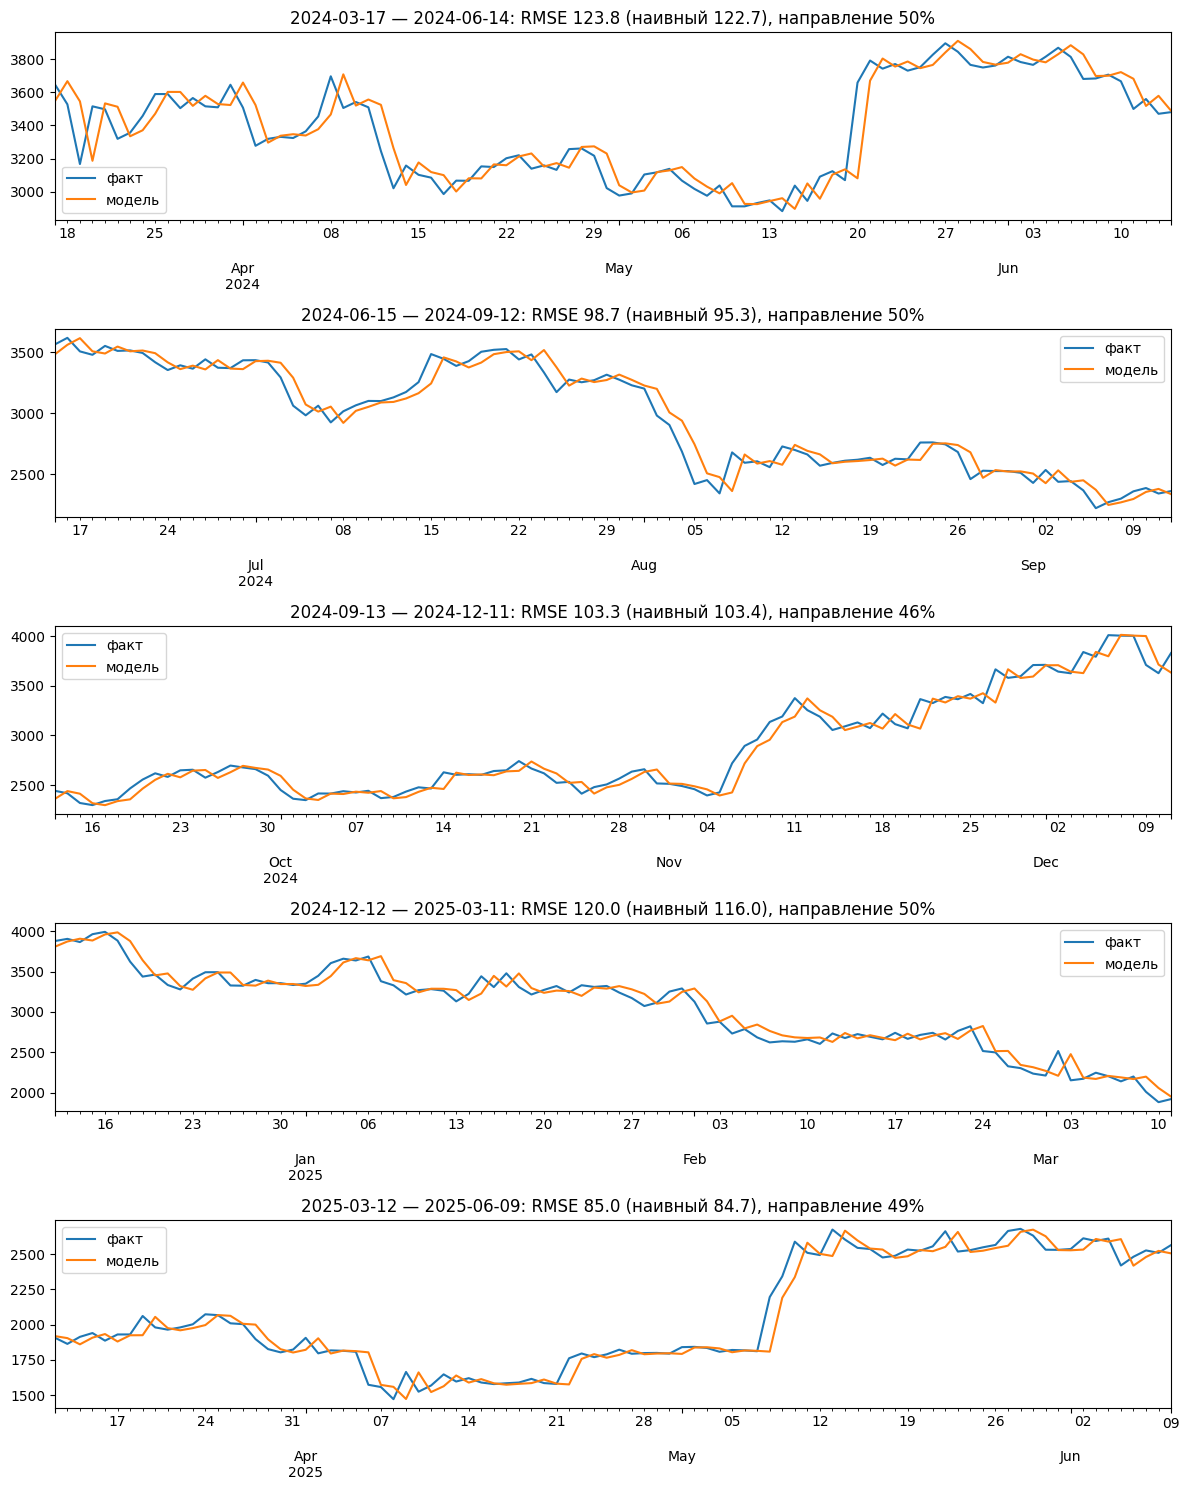

In [6]:
fig, ax = plt.subplots(FOLDS, 1, figsize=(12, 3 * FOLDS))
for a, p, (name, r) in zip(ax, preds, res.iterrows()):
    p.plot(ax=a, title=f"{name}: RMSE {r['RMSE модель']:.1f} (наивный {r['RMSE наивный']:.1f}), направление {r['точность направления, %']:.0f}%")
plt.tight_layout()

## Матрица внимания (последний кусок, усреднение по головам и тестовым окнам)

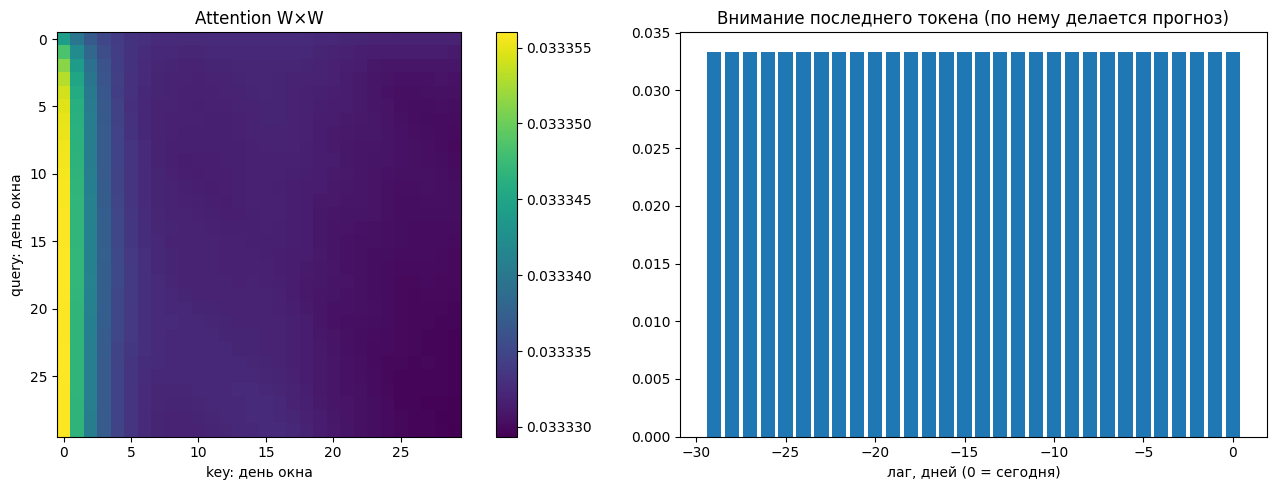

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.2, 1]})
im = ax[0].imshow(attn, cmap="viridis")
ax[0].set(xlabel="key: день окна", ylabel="query: день окна", title="Attention W×W")
plt.colorbar(im, ax=ax[0])
ax[1].bar(np.arange(-W + 1, 1), attn[-1])
ax[1].set(xlabel="лаг, дней (0 = сегодня)", title="Внимание последнего токена (по нему делается прогноз)")
plt.tight_layout()

## Выводы

Направление цен по истории угадывать почти невозможно изза самобалансировки рынка и большого количества шума.